In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
processed_path = '../data/processed/processed.parquet'

df = pd.read_parquet(processed_path)

In [3]:
counts = df.groupby("firm_id")["former"].agg(n_former="sum", n_total="size")
counts["n_current"] = counts["n_total"] - counts["n_former"]

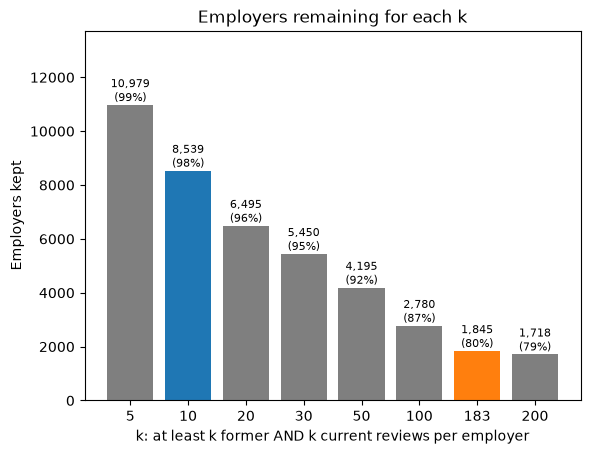

In [4]:
counts["n_min"] = counts[["n_former", "n_current"]].min(axis=1)
ks = [5, 10, 20, 30, 50, 100, 183, 200]
firms_kept = [(counts["n_min"] >= k).sum() for k in ks]
reviews_kept = [counts.loc[counts["n_min"] >= k, "n_total"].sum() / counts["n_total"].sum() * 100 for k in ks]

highlight = {10: "tab:blue", 183: "tab:orange"}
colors = [highlight.get(k, "tab:gray") for k in ks]

plt.bar([str(k) for k in ks], firms_kept, color=colors)
for i, (f, r) in enumerate(zip(firms_kept, reviews_kept)):
    plt.text(i, f, f"{f:,}\n({r:.0f}%)", ha="center", va="bottom", fontsize=8)
plt.ylim(0, max(firms_kept) * 1.25)
plt.xlabel("k: at least k former AND k current reviews per employer")
plt.ylabel("Employers kept")
plt.title("Employers remaining for each k")
plt.show()